In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [43]:
df = pd.read_csv(r"C:\Users\HP\Desktop/Ironhack/WK5/Day-1/amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [44]:
df["isBestSeller"].dtypes

dtype('bool')

In [45]:
## Part 1: Analyzing Best-Seller Trends Across Product Categories


## Crosstab Analysis:

##Create a crosstab between the product category and the isBestSeller status.
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [46]:
## Are there categories where being a best-seller is more prevalent?
crosstab_result_prev = pd.crosstab(df['category'], df['isBestSeller'],normalize=True).sort_values(by=True, ascending=False)

crosstab_result_prev

## best seller is more prevalent in categories like Grocery, Health & personal care and Baby 

isBestSeller,False,True
category,,
Grocery,0.003686,0.000228
Health & Personal Care,0.003690,0.000226
Baby,0.006019,0.000140
Sports & Outdoors,0.342084,0.000135
Power & Hand Tools,0.003418,0.000125
...,...,...
Downhill Ski Boots,0.000525,0.000000
Digital Frames,0.000317,0.000000
Motorbike Chassis,0.000044,0.000000


In [47]:
## Statistical Tests:
## Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

## A p-value=0 which is less than 0.05, indicates a dependent relationship between the two variables.

(36540.20270061387, 0.0)

In [48]:
## Compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")
#The Cramér's V value of 0.122 suggests a weak association between the two variables.

0.1222829439760564

In [49]:
#crosstab_log=crosstab_result.copy()

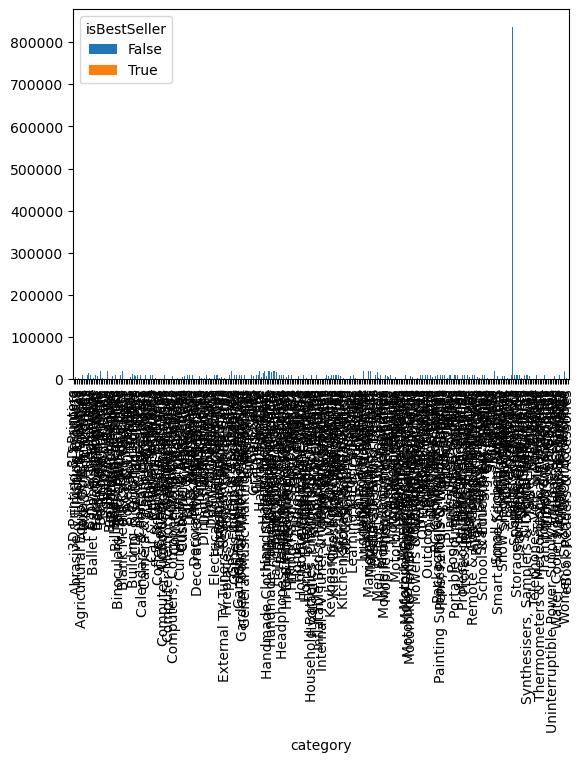

In [50]:
## Visualizations:
## Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

crosstab_result.plot(kind="bar",  stacked=True)
plt.show()

In [51]:
## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

## Preliminary Step: Remove outliers in product prices.
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers



In [52]:
price_outliers = df['price']  # replace 'ColumnName' with your specific column
outliers = tukeys_test_outliers(price_outliers)
print(outliers)

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [53]:
df_new=df[~df["price"].isin(outliers)]

In [54]:
df_new

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [55]:
check=df_new["category"].value_counts().head(20).reset_index()

keep=check["category"]

In [56]:
df_check=df_new[df_new["category"].isin(keep)]

C:\Users\HP\AppData\Local\Temp\ipykernel_24608\1721207321.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


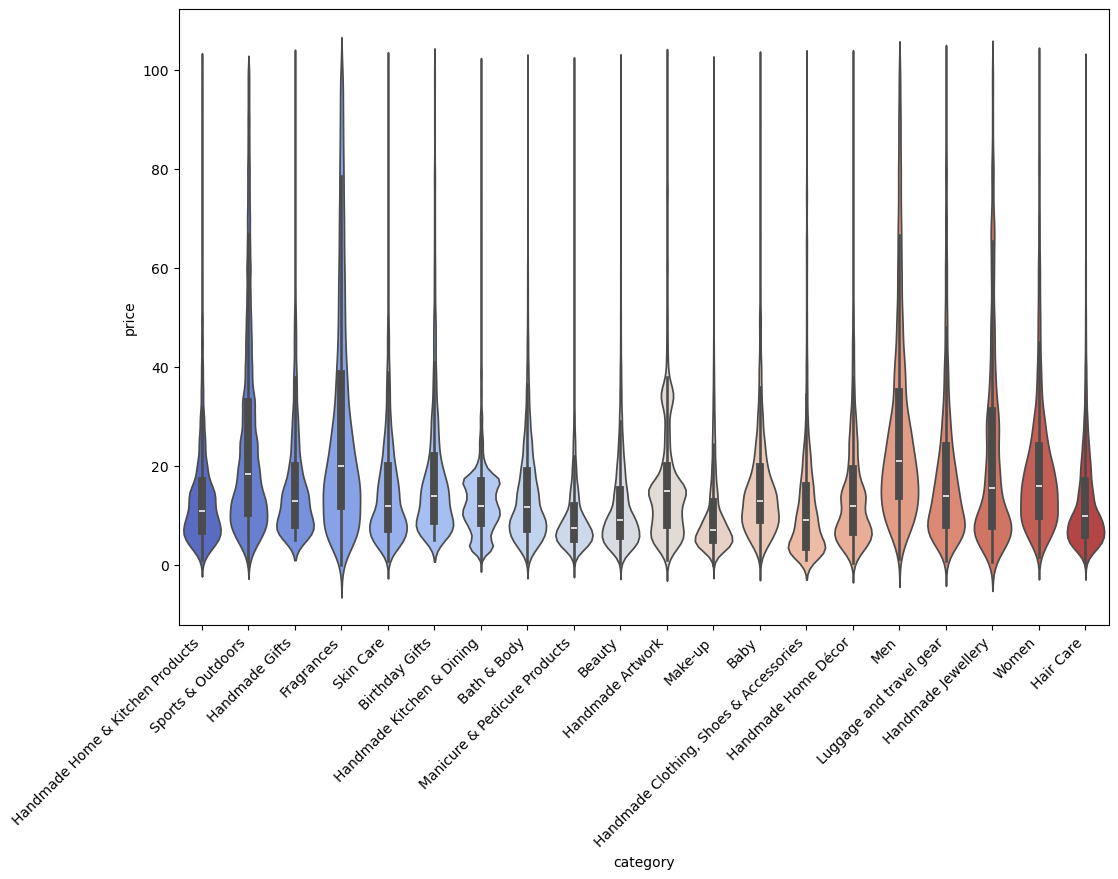

In [57]:
#Violin Plots:
#Use a violin plot to visualize the distribution of price across different product categories.
plt.figure(figsize=(12, 8))
ax = plt.gca()
sns.violinplot(data=df_check, hue='category',x='category', y='price', palette="coolwarm", legend=False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

In [59]:
## Which product category tends to have the highest median price? Don't filter here by top categories.
prod_cat=df_new.groupby('category').agg({'price':"median"}).sort_values(by="price", ascending=False).reset_index()
prod_cat

## Desktop PCs have the highest median price of 74 euros.

,category,price
0,Desktop PCs,74.00
1,Boxing Shoes,69.79
2,Tablets,69.00
3,Graphics Cards,68.54
4,Motherboards,67.92
...,...,...
291,Adapters,7.05
292,Make-up,7.00
293,Signs & Plaques,6.99
294,Arts & Crafts,5.99


In [20]:
## Bar Charts:

## Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
check2=df_new["category"].value_counts().head(10).reset_index()

keep2=check2["category"]
df_check2=df_new[df_new["category"].isin(keep2)]
df_check2

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\HP\AppData\Local\Temp\ipykernel_24608\4220309591.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_check2, x="category", y="price", estimator="mean", palette="coolwarm")
C:\Users\HP\AppData\Local\Temp\ipykernel_24608\4220309591.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


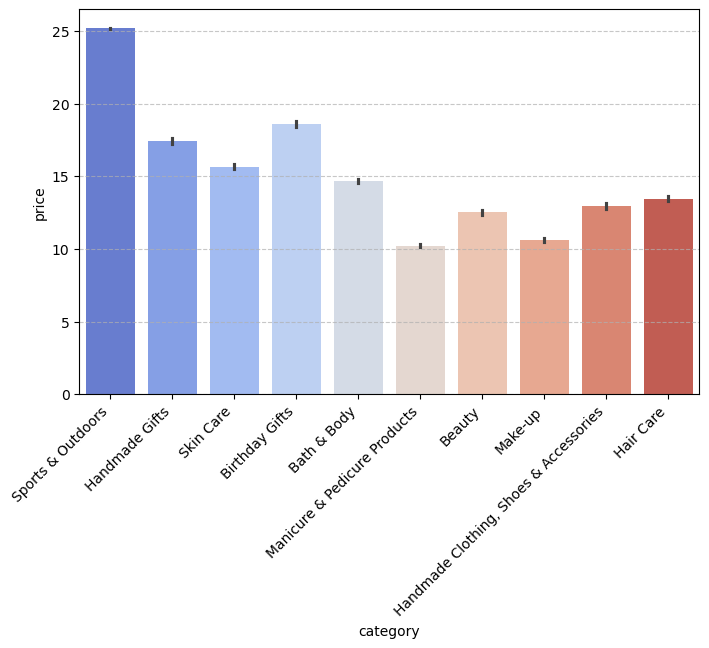

In [41]:
plt.figure(figsize=(8, 5))
ax = plt.gca()
sns.barplot(data=df_check2, x="category", y="price", estimator="mean", palette="coolwarm")
plt.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()


In [42]:
## Which product category commands the highest average price? Don't filter here by top categories.
prod_check=df_new.groupby('category').agg({'price':"mean"}).sort_values(by="price", ascending=False).reset_index()
prod_check

## The motherboards have the highest average price.

,category,price
0,Motherboards,68.772432
1,Boxing Shoes,67.417803
2,Desktop PCs,66.915562
3,Tablets,66.552971
4,Graphics Cards,65.103509
...,...,...
291,Bedding Accessories,8.835220
292,Adapters,8.750197
293,Signs & Plaques,8.210513
294,Arts & Crafts,8.006540


C:\Users\HP\AppData\Local\Temp\ipykernel_24608\131130349.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_check2, x='category', y='stars', palette="coolwarm")
C:\Users\HP\AppData\Local\Temp\ipykernel_24608\131130349.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


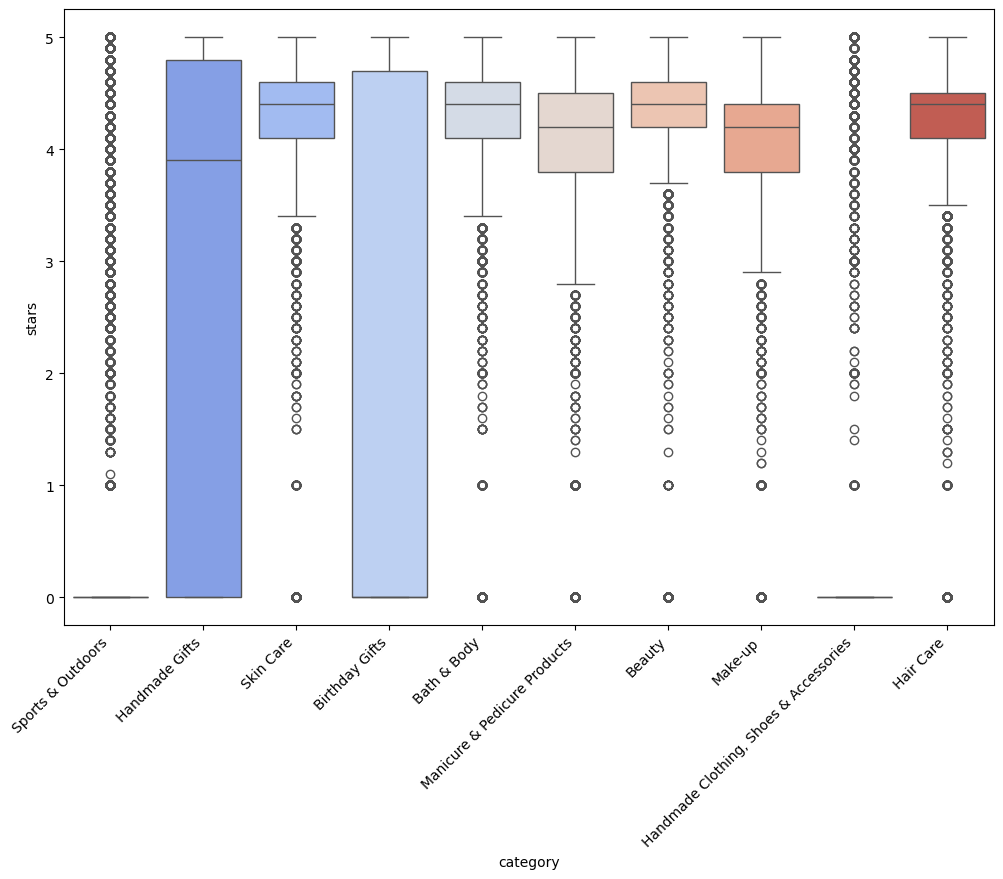

In [66]:
## Box Plots:

## Visualize the distribution of product ratings based on their category using side-by-side box plots
plt.figure(figsize=(12, 8))
ax = plt.gca()
sns.boxplot(data=df_check2, x='category', y='stars', palette="coolwarm")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

In [70]:
### Which category tends to receive the highest median rating from customers? Don't filter here by top categories
prod_rating=df_new.groupby('category').agg({'stars':"mean"}).sort_values(by="stars", ascending=False).reset_index()
prod_rating

## The luxury food and drinks received the highest median rating of 4.54

,category,stars
0,Luxury Food & Drink,4.544140
1,Grocery,4.469414
2,Laptop Accessories,4.449600
3,Health & Personal Care,4.439549
4,Arts & Crafts,4.432942
...,...,...
291,Boxing Shoes,0.160470
292,"Motorbike Handlebars, Controls & Grips",0.134289
293,Motorbike Electrical & Batteries,0.105697
294,3D Printing & Scanning,0.094067


In [71]:
### Part 3: Investigating the Interplay Between Product Prices and Ratings

## Correlation Coefficients:
## Calculate the correlation coefficient between price and stars.
correlation = df_new['price'].corr(df_new['stars'])
correlation

## Is there a significant correlation between product price and its rating?
## ANS: There is no significant correlation between the variables, the negative correlation gotten is extrememly weak.
# AS the price increase, the ratings drop.

-0.07767299878181323

In [72]:
correlation = df_new['price'].corr(df_new['stars'], method='spearman')
correlation
## The spearman's correlation value is a bit more than the pearson's indicating maybe a bit of non linearity in relatiosnhip of both variables

-0.06679697280768307

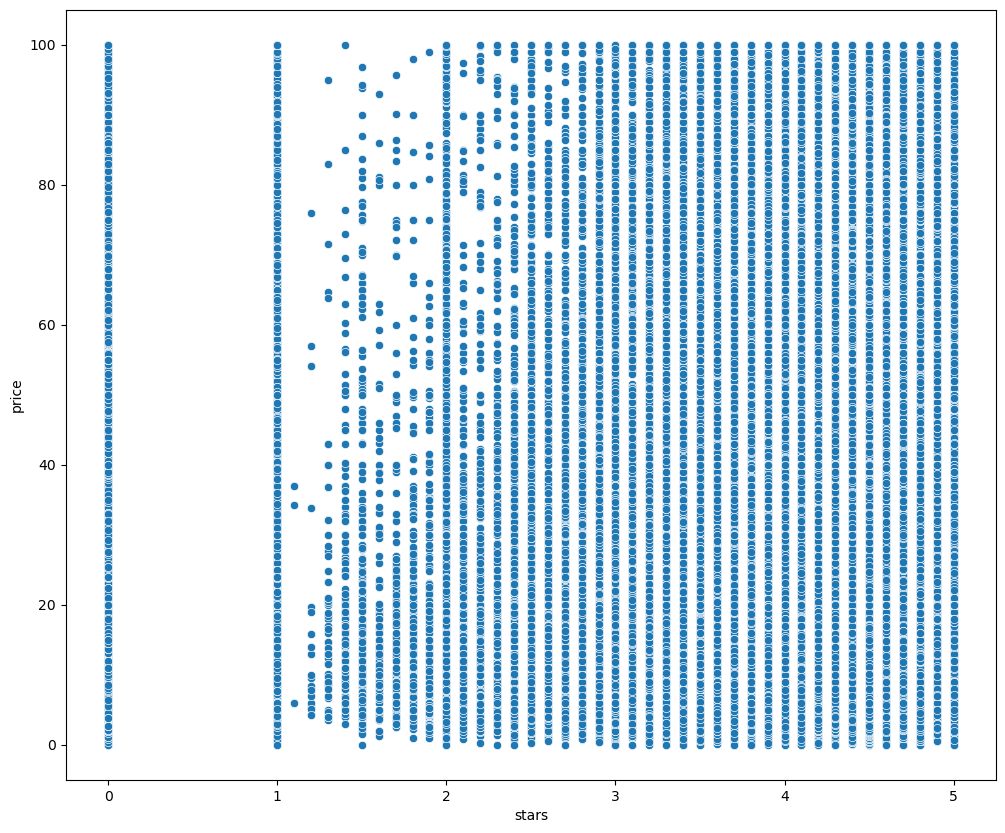

In [76]:
## Visualizations:
##Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

plt.figure(figsize=(12, 10))
sns.scatterplot(data=df_new, x='stars', y='price')
plt.show()

In [83]:
df_numerical=df_new[df_new.select_dtypes("number").columns]
df_numerical

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [ ]:
# Calculating the Spearman correlation coefficients between 'SalePrice' and all other numerical variables
spearman_correlations = df_numerical.corrwith(df['SalePrice'], method='spearman')

# Sorting the correlations for better visualization
spearman_correlations_sorted = spearman_correlations.sort_values(ascending=False)

# Displaying the correlations
spearman_correlations_sorted

In [89]:
correlation_matrix = df_numerical.corr()
correlation_matrix

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.030288,0.020236,0.001717,0.017116
stars,0.030288,1.000000,0.083920,-0.077673,0.113994
reviews,0.020236,0.083920,1.000000,-0.008498,0.105624
price,0.001717,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.017116,0.113994,0.105624,-0.059051,1.000000


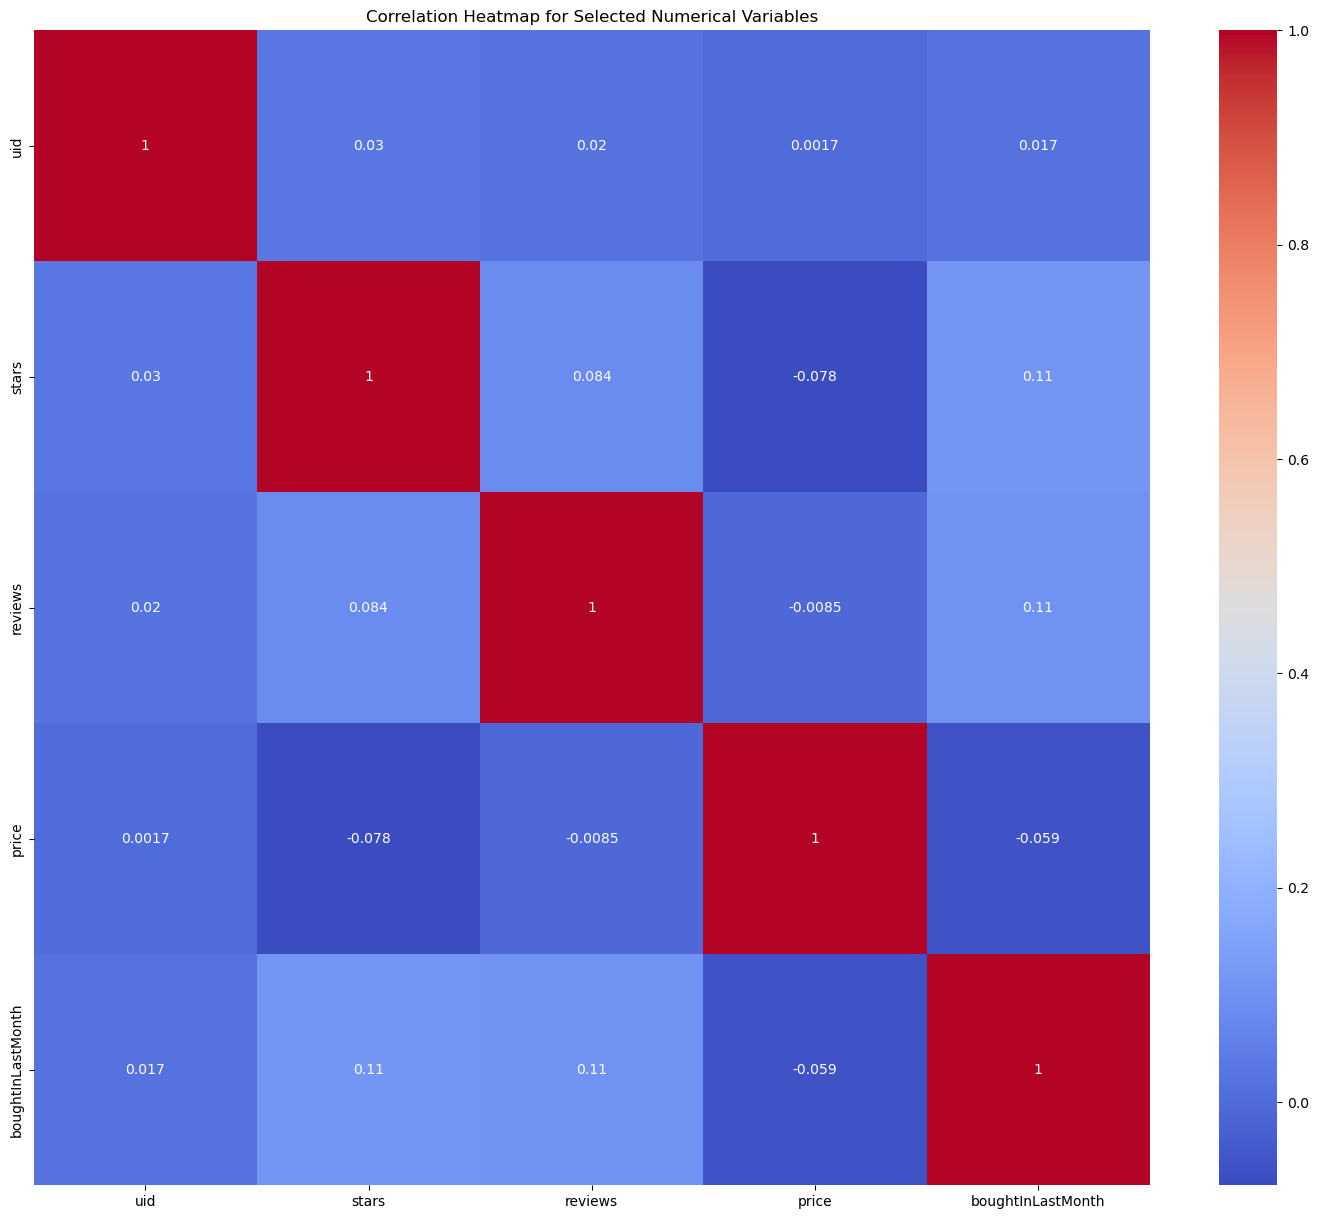

In [84]:
## Use a correlation heatmap to visualize correlations between all numerical variables.
correlation_matrix = df_numerical.corr()
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

In [91]:
cor_sorted=correlation_matrix[abs(correlation_matrix) > 0.5]
cor_sorted

,uid,stars,reviews,price,boughtInLastMonth
uid,1.0,NaN,NaN,NaN,NaN
stars,NaN,1.0,NaN,NaN,NaN
reviews,NaN,NaN,1.0,NaN,NaN
price,NaN,NaN,NaN,1.0,NaN
boughtInLastMonth,NaN,NaN,NaN,NaN,1.0


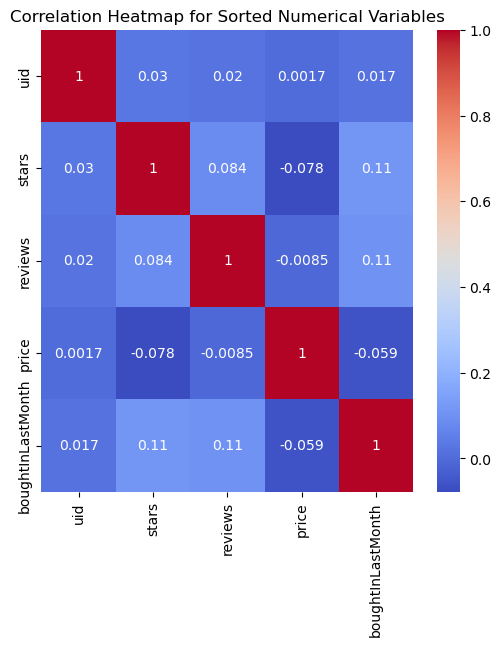

In [92]:
correlations_sorted_top = df_numerical[cor_sorted.index].corr()
plt.figure(figsize=(6, 6))

# Drawing the heatmap for sorted numerical columns
sns.heatmap(correlations_sorted_top, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Sorted Numerical Variables")
plt.show()

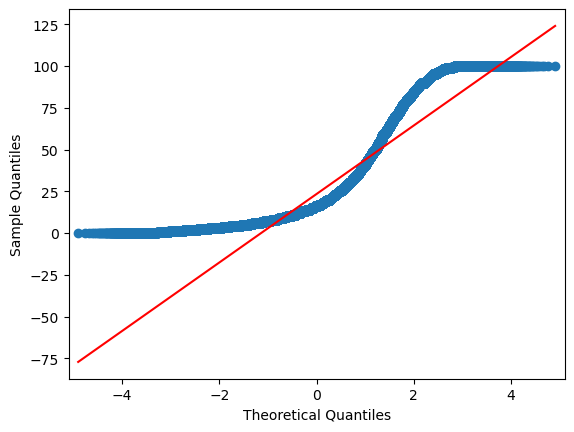

In [94]:
## Examine if product prices typically follow a normal distribution using a QQ plot.
import statsmodels.api as sm

# Generating a Q-Q plot for 'Price' to check if its distribution follows a normal distribution
sm.qqplot(df_numerical['price'], line='s')
plt.show()

## The distribution of price does not follow the normal distribution.